# MCDI505 · Semana 3 — Modelos avanzados (ARFIMA / GARCH)
**Estudiante:** Roberto Moncada · 
**Programa:** Magíster en Ciencia de Datos, UNAB Online
**Curso:** MCDI505, Unidad 3, Semana 3 · 
**Archivo:** `mcdi505_s3rmoncada.ipynb` · 
**Fecha:** Octubre de 2026

**Pregunta de la semana:** ¿la memoria larga o la volatilidad condicional aportan algo al SARIMA en esta serie? Una respuesta negativa bien fundamentada es tan válida como una positiva.


## Hoja de decisiones

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Memoria larga | **No hay memoria larga** en los residuos del SARIMA de la Semana 2; el H > 0,5 se debe al sesgo del método R/S con pocos datos. | Figura 1: la ACF de los 83 residuos no muestra decaimiento lento; solo el rezago 24 (−0,22) alcanza la banda ±0,215. Ljung-Box p = 0,355 / 0,061 / 0,076 (rezagos 12, 24 y 36; 2 parámetros MA descontados). H = 0,652 y d = 0,152. Figura 2: en 500 ruidos blancos (n = 83), el H medio es 0,612 (IC 95 %: 0,392–0,823) y el 37 % supera 0,652.| Agregar un ARFIMA(0,d,0) con d = 0,152. | Se mantiene la diferenciación entera (d = 1 y D = 1) de la Semana 2. La corrección ARFIMA es mínima (−0,25 GWh en promedio) y empeora la validación (fila 3). |
| 2. Volatilidad | **No hay volatilidad condicional**: la varianza de los residuos se puede suponer constante. |**Figura 3:** la ACF de los residuos² no muestra agrupamiento. Ljung-Box p = 0,485 y ARCH-LM (12) p = 0,639, igual que en la Semana 2. El GARCH(1,1) da ω = 0,457, α = 0,066, β = 0,442 y α + β = 0,509 (< 1). En los residuos estandarizados, Ljung-Box p = 0,562 (z) y 0,654 (z²), y ARCH-LM p = 0,832. | Construir los intervalos con la varianza condicional de un GARCH(1,1). | Se mantienen los intervalos del SARIMA con varianza constante. Las bandas GARCH convergen a la varianza incondicional en 2-3 meses (factor 0,96-1,00).|
| 3. Contraste con el modelo clásico | **Ninguna de las dos extensiones mejora al SARIMA** en la validación 2023. | Tabla 1 (GWh, media corregida por sesgo como en la Semana 2): el SARIMA obtiene RMSE/MAE = 6,85/6,40, frente a 7,06/6,64 de SARIMA + ARFIMA y 7,26/6,53 del naive estacional. En la misma tabla, ambos intervalos al 95 % cubren los 12 meses (cobertura de 100 %); el ancho medio es 29,4 GWh (SARIMA) y 29,3 GWh (GARCH). Los 12 errores del SARIMA son positivos (+6,40 GWh). | Considerar como mejora una diferencia de RMSE menor a 0,3 GWh o bandas de pronóstico un 0,4 % más estrechas. | Las diferencias son de alrededor del 3 % del error de un mes y, con 12 meses, podrían deberse al azar. El problema principal del pronóstico es el sesgo de nivel. |
| 4. Selección del modelo | **Se mantiene el modelo B de la Semana 2: SARIMA(0,1,1)(0,1,1)₁₂ con covid**, sobre el logaritmo del consumo. | **Bloques 1-3:** no hay memoria larga (H dentro de lo esperado para ruido blanco), ni efectos ARCH (p = 0,639), ni mejora en el pronóstico (ΔRMSE ARFIMA = +0,21 GWh; misma cobertura). El AIC = −300,9, igual que en la Semana 2.| Se descartaron dos variantes del SARIMA: una con ARFIMA(0,d,0) y otra con bandas de pronóstico GARCH(1,1).| En la Semana 4 se reestima el SARIMA con datos de 2015-2023 y se pronostica 2024. Hay que prestar atención al sesgo de nivel de 2023 y al MA estacional, que está muy cerca del límite de invertibilidad (−0,981).|

## 0. Configuración, datos y punto de partida

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

In [2]:
# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# No necesita modificarlas.
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
df = pd.read_csv("consumo_electrico_litoral_depurado.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Partición oficial: entrenamiento 2015-2022, validación 2023. 2024 no se utiliza esta semana.
H = 12
log_train, log_val = log_y[:"2022-12"], log_y["2023-01":"2023-12"]
y_val = y["2023-01":"2023-12"]
print(f"Entrenamiento: {len(log_train)} meses | Validación: {len(log_val)} meses")

Entrenamiento: 96 meses | Validación: 12 meses


In [4]:
# ==============================================================================
# COMPLETE: el modelo SARIMA que seleccionó en la Sumativa 2 (misma especificación)
# ==============================================================================
# Sumativa 2: logaritmo, d = 1 y D = 1 (ADF + KPSS + ACF(12)); se eligió el modelo B (tipo «airline»)
# por puntaje AIC/BIC/RMSE y MAE con origen móvil, entre los candidatos que pasaron Ljung-Box (12 y 24).
ORDEN = (0, 1, 1)                  # (p, d, q)
ORDEN_ESTACIONAL = (0, 1, 1, 12)   # (P, D, Q, s)
USAR_COVID = True                  # indicador covid (mar-2020 a dic-2021) como regresor, igual que en la Sumativa 2

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

In [5]:
# Reestimación del SARIMA sobre el entrenamiento (escala logarítmica)
X_train = df[["covid"]][:"2022-12"] if USAR_COVID else None
X_val = df[["covid"]].loc["2023-01":"2023-12"] if USAR_COVID else None

sarima = SARIMAX(log_train, exog=X_train, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]      # se descartan las primeras d + D·s observaciones
residuos = sarima.resid.iloc[inicio:]

pron = sarima.get_forecast(H, exog=X_val)
media_log = pron.predicted_mean
ic_log = pron.conf_int(alpha=0.05)
sd_log = (ic_log.iloc[:, 1] - media_log) / 1.96

naive = y["2022-01":"2022-12"].to_numpy()                          # naive estacional
print(f"AIC = {sarima.aic:.1f} | residuos utilizables: {len(residuos)}")
print(sarima.summary().tables[1])
print(f"Efecto covid: {100 * (np.exp(sarima.params['covid']) - 1):.1f} % | "
      f"mín. |raíz MA| = {np.abs(sarima.maroots).min():.3f} (1 = frontera de invertibilidad)")

AIC = -300.9 | residuos utilizables: 83
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid         -0.0617      0.017     -3.629      0.000      -0.095      -0.028
ma.L1         -0.2050      0.086     -2.395      0.017      -0.373      -0.037
ma.S.L12      -0.9808      2.244     -0.437      0.662      -5.378       3.417
sigma2         0.0011      0.002      0.461      0.645      -0.003       0.006
Efecto covid: -6.0 % | mín. |raíz MA| = 1.002 (1 = frontera de invertibilidad)


**Punto de partida.** Se utilizó el modelo seleccionado en la Sumativa 2: SARIMA(0,1,1)(0,1,1)₁₂ con la variable covid (modelo B, tipo «airline»), estimado con statsmodels (Seabold y Perktold, 2010) sobre el logaritmo del consumo, con datos de entrenamiento de 2015-2022. Al volver a estimarlo se obtuvo el mismo AIC (−300,9) y el mismo efecto de la COVID-19 (−6,0 %), por lo que corresponde a la misma especificación.
Además, el parámetro MA estacional se mantiene cerca del límite de invertibilidad (−0,981), igual que en la Semana 2 (Box et al., 2015). Debido a la diferenciación aplicada, se eliminan las primeras d + D·s = 13 observaciones, quedando 83 residuos para el análisis.
Siguiendo la guía, todas las pruebas y diagnósticos de esta semana se realizan sobre estos 83 residuos y no sobre la serie original.

## 1. Modelamiento de memoria larga (ARFIMA / diferenciación fraccional)

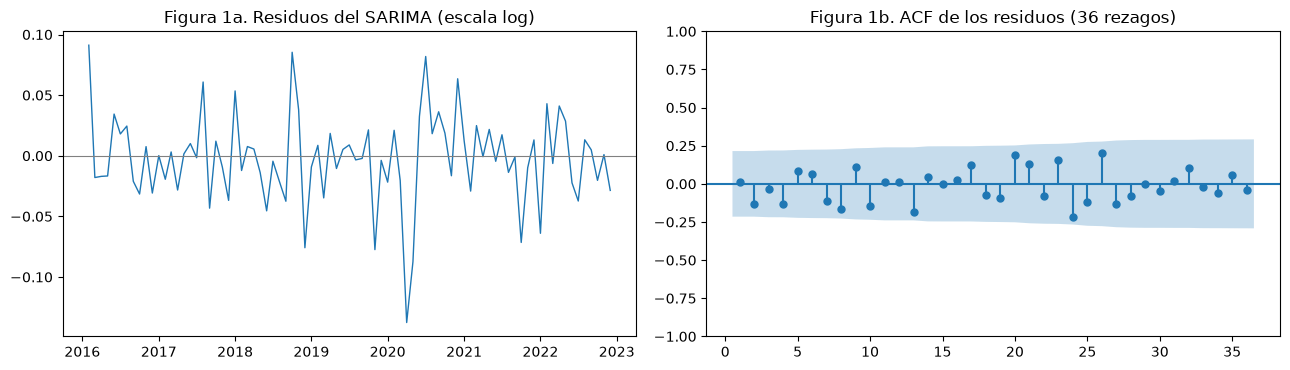

Banda ±1,96/√n = ±0.215 | rezagos fuera de la banda: [24]
Ljung–Box sobre los residuos (2 parámetros MA descontados, como en la Sumativa 2):
    lb_stat  lb_pvalue
12   11.034      0.355
24   33.085      0.061
36   46.410      0.076

Hurst (R/S) = 0.652  ->  d = 0.152


Ruido blanco, n = 83: H medio = 0.612 | IC 95 % = [0.392, 0.823] | P(H_ruido >= H_res) = 0.37


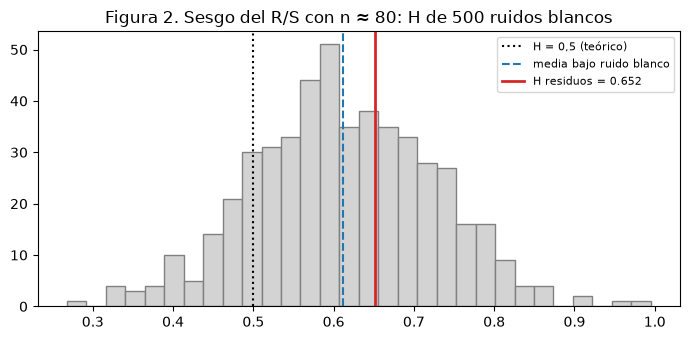


Corrección ARFIMA en log (h = 1..12): [-0.0055 -0.0036 -0.0028 -0.0024 -0.0021 -0.0019 -0.0017 -0.0016 -0.0015
 -0.0014 -0.0013 -0.0013]
Efecto medio sobre el pronóstico: -0.25 GWh


In [6]:
from statsmodels.tsa.stattools import acf

# (a) ACF de los residuos hasta el rezago 36
banda = 1.96 / np.sqrt(len(residuos))
acf_res = acf(residuos, nlags=36)[1:]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(residuos.index, residuos, lw=1)
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set_title("Figura 1a. Residuos del SARIMA (escala log)")
plot_acf(residuos, lags=36, ax=ax[1], zero=False)
ax[1].set_title("Figura 1b. ACF de los residuos (36 rezagos)")
plt.tight_layout(); plt.show()

print(f"Banda ±1,96/√n = ±{banda:.3f} | rezagos fuera de la banda: "
      f"{[int(k) + 1 for k in np.where(np.abs(acf_res) > banda)[0]]}")
print("Ljung–Box sobre los residuos (2 parámetros MA descontados, como en la Sumativa 2):")
print(acorr_ljungbox(residuos, lags=[12, 24, 36], model_df=2).round(3))

# (b) Exponente de Hurst y d = H - 0.5
H_res = calcular_exponente_hurst(residuos)
d_res = H_res - 0.5
print(f"\nHurst (R/S) = {H_res:.3f}  ->  d = {d_res:.3f}")

# (c) ¿Qué tan confiable es con ~80 observaciones? Distribución de H bajo ruido blanco del mismo tamaño
rng = np.random.default_rng(SEMILLA)
H_ruido = np.array([calcular_exponente_hurst(rng.standard_normal(len(residuos))) for _ in range(500)])
print(f"Ruido blanco, n = {len(residuos)}: H medio = {H_ruido.mean():.3f} | "
      f"IC 95 % = [{np.percentile(H_ruido, 2.5):.3f}, {np.percentile(H_ruido, 97.5):.3f}] | "
      f"P(H_ruido >= H_res) = {np.mean(H_ruido >= H_res):.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(H_ruido, bins=30, color="lightgrey", edgecolor="grey")
ax.axvline(0.5, color="black", ls=":", label="H = 0,5 (teórico)")
ax.axvline(H_ruido.mean(), color="tab:blue", ls="--", label="media bajo ruido blanco")
ax.axvline(H_res, color="tab:red", lw=2, label=f"H residuos = {H_res:.3f}")
ax.set_title("Figura 2. Sesgo del R/S con n ≈ 80: H de 500 ruidos blancos")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# (d) Pronóstico con corrección ARFIMA(0,d,0)
corr_arfima = correccion_arfima(residuos, d_res, H)
media_log_arfima = media_log + corr_arfima
pron_sarima = np.exp(media_log + sd_log ** 2 / 2)          # media corregida por sesgo, como en la Sumativa 2
pron_arfima = np.exp(media_log_arfima + sd_log ** 2 / 2)   # misma corrección para el SARIMA + ARFIMA
print("\nCorrección ARFIMA en log (h = 1..12):", np.round(corr_arfima, 4))
print(f"Efecto medio sobre el pronóstico: {np.mean(pron_arfima - pron_sarima):+.2f} GWh")

**Interpretación.** Se analizó si los 83 residuos del modelo SARIMA presentaban memoria larga, es decir, si persistían efectos de largo plazo que no fueron capturados por d = 1 y D = 1 (Granger y Joyeux, 1980; Hosking, 1981).
La ACF (Figura 1) no muestra el decaimiento lento típico de la memoria larga. Solo el rezago 24 (−0,22) queda apenas fuera de la banda ±0,215, y un rezago aislado no es un decaimiento lento. La prueba de Ljung-Box no rechaza ruido blanco (p = 0,355, 0,061 y 0,076 en los rezagos 12, 24 y 36; Ljung y Box, 1978).
Luego se calculó el exponente de Hurst, que fue H = 0,652 (d = 0,152); sin embargo, al simular 500 ruidos blancos del mismo tamaño (Figura 2), el promedio fue H = 0,612 y el 37 % superó 0,652 (Hurst, 1951; Bianchi, 2023), por lo que el resultado es compatible con una serie sin memoria larga.
Además, el ARFIMA(0,d,0), estimado como contraste, solo genera una corrección muy pequeña de −0,25 GWh en promedio y va en sentido contrario al error de 2023.
**Conclusión:** no hay evidencia de memoria larga, por lo que se mantiene la diferenciación entera de la Semana 2.

## 2. Modelamiento de volatilidad (GARCH)

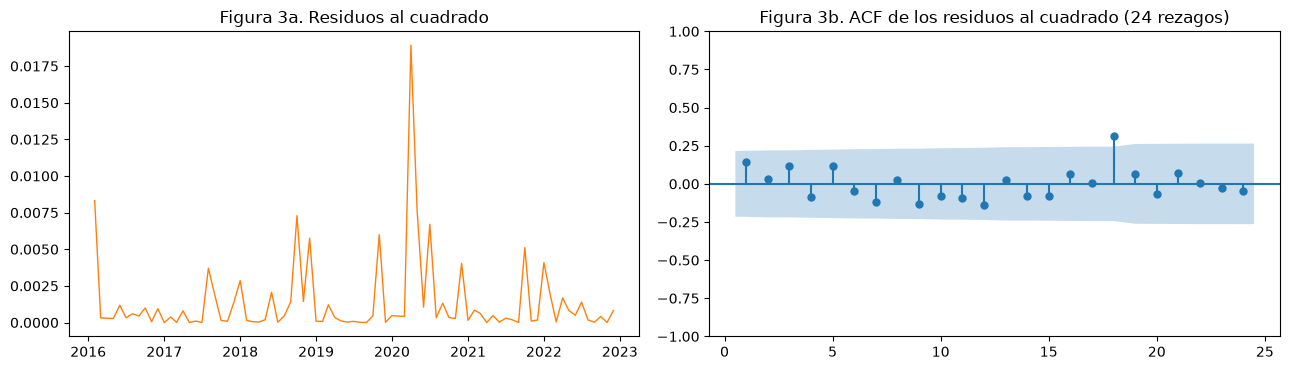

Ljung–Box residuos² (12): Q = 11.53, p = 0.485
ARCH-LM (12):             LM = 9.73, p = 0.639

GARCH(1,1): omega = 0.457 | alpha = 0.066 | beta = 0.442 | persistencia = 0.509 | convergencia = True
Residuos estandarizados: Ljung–Box z (12 / 24) p = 0.562 / 0.121 | Ljung–Box z² (12) p = 0.654 | ARCH-LM (12) p = 0.832


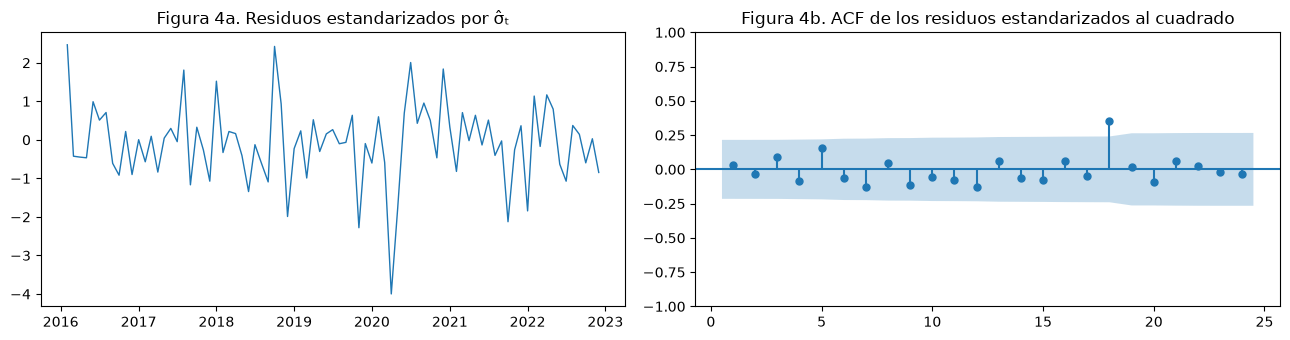

Factor de escala de la desviación estándar condicional: [0.964 0.982 0.991 0.995 0.998 0.999 0.999 1.    1.    1.    1.    1.   ]


In [7]:
# (a) Detección formal sobre los residuos del SARIMA
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(residuos.index, residuos ** 2, lw=1, color="tab:orange")
ax[0].set_title("Figura 3a. Residuos al cuadrado")
plot_acf(residuos ** 2, lags=24, ax=ax[1], zero=False)
ax[1].set_title("Figura 3b. ACF de los residuos al cuadrado (24 rezagos)")
plt.tight_layout(); plt.show()

lb_cuad = acorr_ljungbox(residuos ** 2, lags=[12])
lm_stat, lm_p, _, _ = het_arch(residuos, nlags=12)
print(f"Ljung–Box residuos² (12): Q = {lb_cuad.lb_stat.iloc[0]:.2f}, p = {lb_cuad.lb_pvalue.iloc[0]:.3f}")
print(f"ARCH-LM (12):             LM = {lm_stat:.2f}, p = {lm_p:.3f}")

# (b) GARCH(1,1) por MLE con restricción alpha + beta < 1
g = estimar_garch11(residuos, H)
print(f"\nGARCH(1,1): omega = {g['omega']:.3f} | alpha = {g['alpha']:.3f} | beta = {g['beta']:.3f} | "
      f"persistencia = {g['persistencia']:.3f} | convergencia = {g['convergencia']}")

# (c) Diagnóstico sobre los residuos estandarizados por sigma_t
z = g["residuos_estandarizados"]
lb_z_nivel = acorr_ljungbox(z, lags=[12, 24])
lb_z = acorr_ljungbox(z ** 2, lags=[12])
lm_z = het_arch(z, nlags=12)
print(f"Residuos estandarizados: Ljung–Box z (12 / 24) p = {lb_z_nivel.lb_pvalue.iloc[0]:.3f} / {lb_z_nivel.lb_pvalue.iloc[1]:.3f} | "
      f"Ljung–Box z² (12) p = {lb_z.lb_pvalue.iloc[0]:.3f} | ARCH-LM (12) p = {lm_z[1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(residuos.index, z, lw=1)
ax[0].set_title("Figura 4a. Residuos estandarizados por σ̂ₜ")
plot_acf(z ** 2, lags=24, ax=ax[1], zero=False)
ax[1].set_title("Figura 4b. ACF de los residuos estandarizados al cuadrado")
plt.tight_layout(); plt.show()

# (d) Bandas GARCH al 95 % en GWh
print("Factor de escala de la desviación estándar condicional:", np.round(g["escala_futura"], 3))
inf_garch = np.exp(media_log - 1.96 * sd_log * g["escala_futura"])
sup_garch = np.exp(media_log + 1.96 * sd_log * g["escala_futura"])
inf_sarima, sup_sarima = np.exp(ic_log.iloc[:, 0]), np.exp(ic_log.iloc[:, 1])

**Interpretación.** Se evaluó si los residuos presentan volatilidad condicional, es decir, si los períodos con alta variación tienden a repetirse (Engle, 1982).

La ACF de los residuos al cuadrado (Figura 3) no muestra un patrón claro; solo destaca el rezago 18 (0,31). Además, las pruebas 
Ljung-Box sobre los residuos² (p = 0,485) y ARCH-LM (p = 0,639) no rechazan la hipótesis de varianza constante, confirmando lo observado en la Semana 2 (Universidad Andrés Bello, s. f., §3.3).

Como contraste, se estimó un GARCH(1,1) (Bollerslev, 1986), obteniendo ω = 0,457, α = 0,066 y β = 0,442. La persistencia es baja (α + β = 0,509): el factor de escala pasa de 0,96 a 1,00 en 2 o 3 meses, por lo que las bandas GARCH son casi iguales a las del SARIMA.

Los residuos estandarizados tampoco muestran estructura (Figura 4): Ljung-Box p = 0,562 en nivel y 0,654 en cuadrados, y ARCH-LM p = 0,832 (Universidad Andrés Bello, s. f., §3.5).

Por otro lado, el consumo mensual del segmento comercial sigue principalmente patrones de estacionalidad y actividad económica, por lo que no presenta las fluctuaciones típicas de los precios financieros. Además, el impacto de la pandemia se refleja como un cambio de nivel (covid −6,0 %) y no como un aumento de la volatilidad. Por eso, la incertidumbre mensual puede considerarse prácticamente constante.

**Conclusión:** no hay evidencia de volatilidad condicional, por lo que el supuesto de varianza constante del SARIMA es adecuado para esta serie.

## 3. Contraste con el modelo clásico y consistencia de conclusiones

Tabla 1. Contraste en la validación 2023: RMSE y MAE en GWh (pronósticos puntuales con media corregida por sesgo, exp(μ + σ²/2), como en la Sumativa 2); cobertura y ancho medio del intervalo al 95 % (sin corrección)


,RMSE,MAE,ΔRMSE vs SARIMA,Cobertura,Ancho medio,Meses dentro
SARIMA (varianza constante),6.854,6.398,0.0,1.0,29.445,12/12
"SARIMA + ARFIMA(0,d,0)",7.063,6.643,0.21,—,—,—
"SARIMA + bandas GARCH(1,1)",6.854,6.398,0.0,1.0,29.328,12/12
Naive estacional,7.263,6.528,0.409,—,—,—


Referencia sin corrección de sesgo (mediana): RMSE = 7.13 GWh, MAE = 6.68 GWh
Errores del SARIMA (real - pronóstico): media = +6.40 GWh | meses con error positivo = 12/12


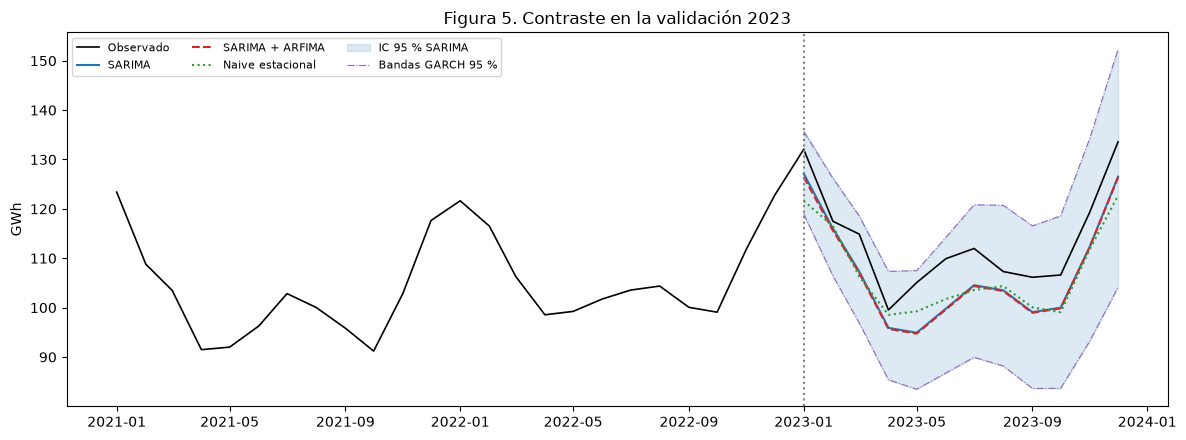

In [8]:
# Tabla única de contraste (validación 2023): precisión puntual en GWh e intervalos al 95 %
# El GARCH no cambia el pronóstico puntual; solo las bandas. El ARFIMA y el naive no tienen intervalo propio.
tabla_contraste = pd.DataFrame({
    "SARIMA (varianza constante)": metricas(y_val, pron_sarima) | cobertura_y_ancho(y_val, inf_sarima, sup_sarima),
    "SARIMA + ARFIMA(0,d,0)": metricas(y_val, pron_arfima),
    "SARIMA + bandas GARCH(1,1)": metricas(y_val, pron_sarima) | cobertura_y_ancho(y_val, inf_garch, sup_garch),
    "Naive estacional": metricas(y_val, naive),
}).T
tabla_contraste["ΔRMSE vs SARIMA"] = tabla_contraste["RMSE"] - tabla_contraste.loc["SARIMA (varianza constante)", "RMSE"]
tabla_contraste["Meses dentro"] = [f"{round(v * H)}/{H}" if pd.notna(v) else None for v in tabla_contraste["Cobertura"]]
tabla_contraste = tabla_contraste[["RMSE", "MAE", "ΔRMSE vs SARIMA", "Cobertura", "Ancho medio", "Meses dentro"]]
print("Tabla 1. Contraste en la validación 2023: RMSE y MAE en GWh (pronósticos puntuales con media corregida por sesgo, "
      "exp(μ + σ²/2), como en la Sumativa 2); cobertura y ancho medio del intervalo al 95 % (sin corrección)")
display(tabla_contraste.round(3).astype(object).where(tabla_contraste.notna(), "—"))

# Referencia: sin corrección de sesgo, exp(μ) es la mediana (como en la plantilla)
pron_sarima_mediana = np.exp(media_log)
print(f"Referencia sin corrección de sesgo (mediana): RMSE = {metricas(y_val, pron_sarima_mediana)['RMSE']:.2f} GWh, "
      f"MAE = {metricas(y_val, pron_sarima_mediana)['MAE']:.2f} GWh")

# Sesgo: ¿los errores tienen signo sistemático?
error_sarima = y_val.to_numpy() - pron_sarima.to_numpy()
print(f"Errores del SARIMA (real - pronóstico): media = {error_sarima.mean():+.2f} GWh | "
      f"meses con error positivo = {(error_sarima > 0).sum()}/{H}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y["2021-01":"2023-12"].index, y["2021-01":"2023-12"], color="black", lw=1.2, label="Observado")
ax.plot(y_val.index, pron_sarima, color="tab:blue", label="SARIMA")
ax.plot(y_val.index, pron_arfima, color="tab:red", ls="--", label="SARIMA + ARFIMA")
ax.plot(y_val.index, naive, color="tab:green", ls=":", label="Naive estacional")
ax.fill_between(y_val.index, inf_sarima, sup_sarima, color="tab:blue", alpha=0.15, label="IC 95 % SARIMA")
ax.plot(y_val.index, inf_garch, color="tab:purple", lw=0.8, ls="-.", label="Bandas GARCH 95 %")
ax.plot(y_val.index, sup_garch, color="tab:purple", lw=0.8, ls="-.")
ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":")
ax.set_ylabel("GWh"); ax.set_title("Figura 5. Contraste en la validación 2023")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.** Se compararon los modelos con los datos de 2023 en GWh (Hyndman y Athanasopoulos, 2021). El ARFIMA se evaluó en los pronósticos puntuales y el GARCH en los intervalos (Universidad Andrés Bello, s. f., §7).

En el pronóstico puntual (Tabla 1), la corrección ARFIMA no ayuda, sino que empeora un poco: el RMSE sube de 6,85 a 7,06 GWh y el MAE de 6,40 a 6,64 GWh. La diferencia (+0,21 GWh) es cerca del 3 % del error de un mes, y con 12 meses puede ser solo azar (Universidad Andrés Bello, s. f., §4.5). El naive estacional queda por detrás en ambas métricas (RMSE 7,26 y MAE 6,53 GWh). Como en la Semana 2, los pronósticos se retransforman con la media corregida por sesgo, exp(μ + σ²/2), así que las métricas son comparables entre semanas.

En la misma Tabla 1, los intervalos del SARIMA y del GARCH cubren los 12 meses y tienen anchos muy similares (29,4 y 29,3 GWh).

Por otro lado, cada modelo mantiene algunas limitaciones. El SARIMA presenta un sesgo de nivel, con 12 de 12 errores positivos y un sesgo promedio de +6,40 GWh; el ARFIMA apenas corrige −0,25 GWh y lo hace en dirección contraria al sesgo. Además, las bandas GARCH son solo un 0,4 % más angostas y vuelven a una varianza constante al tercer mes.

**Conclusión:** ni el ARFIMA ni el GARCH mejoran los resultados del SARIMA.


## 4. Selección del modelo con evidencia cuantitativa

Tabla 2. Pronóstico de validación 2023 del modelo elegido


,Observado (GWh),Pronóstico (GWh),Inferior 95 %,Superior 95 %,Error,Dentro del IC
2023-01,132.06,127.13,118.72,135.98,4.93,True
2023-02,117.49,116.02,106.31,126.37,1.47,True
2023-03,114.88,107.32,96.81,118.64,7.56,True
2023-04,99.53,95.90,85.34,107.40,3.63,True
2023-05,105.07,94.92,83.44,107.53,10.15,True
2023-06,109.91,99.79,86.75,114.24,10.12,True
2023-07,111.98,104.55,89.94,120.84,7.43,True
2023-08,107.31,103.51,88.18,120.74,3.80,True
2023-09,106.15,99.09,83.63,116.56,7.06,True
2023-10,106.61,100.00,83.66,118.58,6.61,True


SARIMA(0, 1, 1)x(0, 1, 1, 12) + covid | AIC = -300.9 | RMSE = 6.854 | MAE = 6.398 | Cobertura = 1.000 | Ancho medio = 29.445


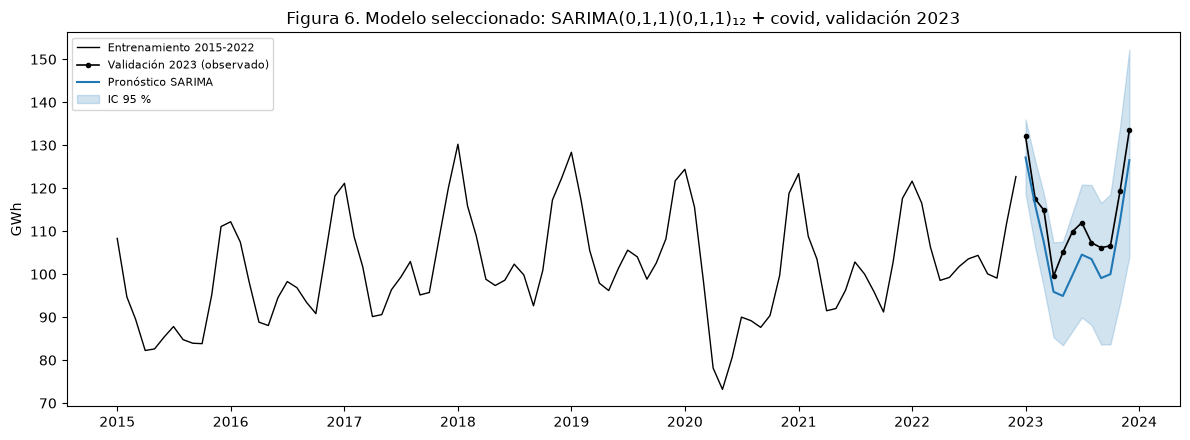

In [9]:
# Modelo elegido: SARIMA(0,1,1)(0,1,1)12 + covid, en log, con su intervalo al 95 % de varianza constante
pronostico_final = pd.DataFrame({
    "Observado (GWh)": y_val,
    "Pronóstico (GWh)": pron_sarima,
    "Inferior 95 %": inf_sarima,
    "Superior 95 %": sup_sarima,
})
pronostico_final["Error"] = pronostico_final["Observado (GWh)"] - pronostico_final["Pronóstico (GWh)"]
pronostico_final["Dentro del IC"] = ((pronostico_final["Observado (GWh)"] >= pronostico_final["Inferior 95 %"]) &
                                     (pronostico_final["Observado (GWh)"] <= pronostico_final["Superior 95 %"]))
pronostico_final.index = pronostico_final.index.strftime("%Y-%m")
print("Tabla 2. Pronóstico de validación 2023 del modelo elegido")
display(pronostico_final.round(2))

resumen = metricas(y_val, pron_sarima) | cobertura_y_ancho(y_val, inf_sarima, sup_sarima)
print(f"SARIMA{ORDEN}x{ORDEN_ESTACIONAL} + covid | AIC = {sarima.aic:.1f} | "
      + " | ".join(f"{k} = {v:.3f}" for k, v in resumen.items()))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(log_train.index, np.exp(log_train), color="black", lw=1, label="Entrenamiento 2015-2022")
ax.plot(y_val.index, y_val, color="black", lw=1.2, marker="o", ms=3, label="Validación 2023 (observado)")
ax.plot(y_val.index, pron_sarima, color="tab:blue", lw=1.5, label="Pronóstico SARIMA")
ax.fill_between(y_val.index, inf_sarima, sup_sarima, color="tab:blue", alpha=0.2, label="IC 95 %")
ax.set_ylabel("GWh"); ax.set_title("Figura 6. Modelo seleccionado: SARIMA(0,1,1)(0,1,1)₁₂ + covid, validación 2023")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.** Como modelo seleccionado se mantiene el SARIMA(0,1,1)(0,1,1)₁₂ con la variable covid (modelo B, tipo «airline»), estimado sobre el logaritmo del consumo (Tabla 2 y Figura 6).

La decisión se basa en que no se encontró evidencia de memoria larga (Ljung-Box no rechaza en ningún rezago, p ≥ 0,06, y H = 0,652 es compatible con ruido blanco), ni de volatilidad condicional (ARCH-LM p = 0,639, α = 0,066 y persistencia 0,509). Además, las extensiones evaluadas no mejoran el desempeño: el ARFIMA aumenta el RMSE en 0,21 GWh y el GARCH logra la misma cobertura (12/12) con un ancho de intervalo muy similar. Por ello, se descartan SARIMA + ARFIMA(0,d,0) y SARIMA con bandas GARCH(1,1).

Los pronósticos de 2023 subestimaron el consumo en los 12 meses. Los errores fueron desde +1,47 GWh en febrero hasta +10,15 GWh en mayo, con un sesgo promedio de +6,40 GWh, equivalente al 5,6 % del consumo medio de 2023 (113,66 GWh). Aunque todos los valores reales quedaron dentro del IC 95 %, el intervalo fue amplio (29,4 GWh, cerca del 26 % del nivel).

En la Semana 4 se reestimará el modelo con datos de 2015-2023 para pronosticar 2024. También se revisará el sesgo observado en 2023 (+6,40 GWh) y el parámetro MA estacional (−0,981), cercano al límite de invertibilidad. Si fuera necesario mejorar el modelo, una alternativa sería incorporar variables externas como la temperatura (SARIMAX).

## Conclusiones

1. **Memoria larga.** No se encontró evidencia de memoria larga. Aunque H = 0,652 (d = 0,152), este valor es compatible con ruido blanco en una muestra de 83 datos, y Ljung-Box no rechaza ruido blanco hasta el rezago 36 (p ≥ 0,06).

2. **Volatilidad.** Tampoco se encontró volatilidad condicional (Ljung-Box sobre los residuos² p = 0,485; ARCH-LM p = 0,639). En el GARCH, α = 0,066 y la persistencia es 0,509, y sus residuos estandarizados no dejan estructura (Ljung-Box p = 0,562 y 0,654).

3. **Contraste.** El ARFIMA empeora levemente el RMSE (de 6,85 a 7,06 GWh) y el GARCH mantiene la misma cobertura (12/12) con un ancho cercano a 29 GWh.

4. **Selección.** Se mantiene el SARIMA(0,1,1)(0,1,1)₁₂ + covid porque ni la memoria larga ni la volatilidad aportan mejoras.

5. **Limitaciones.** La validación se realizó con solo 12 meses de datos, por lo que los resultados deben interpretarse con cautela. Además, el principal problema del modelo sigue siendo el sesgo de +6,40 GWh observado en 2023. Otra limitación es que el método R/S puede ser poco confiable con solo 83 datos, y que únicamente se evaluaron las especificaciones más simples: ARFIMA(0,d,0) y GARCH(1,1).

## Referencias (APA)

Bianchi, F. M. (2023). *Time series analysis with Python* [Repositorio de GitHub]. https://github.com/FilippoMB/python-time-series-handbook

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Granger, C. W. J., y Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *Journal of Time Series Analysis, 1*(1), 15–29. https://doi.org/10.1111/j.1467-9892.1980.tb00297.x

Hosking, J. R. M. (1981). Fractional differencing. *Biometrika, 68*(1), 165–176. https://doi.org/10.1093/biomet/68.1.165

Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers, 116*(1), 770–799.

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Notebook de la Sesión 3 y guía de compañía de la Semana 3* [Material de curso]. UNAB Online.

## Declaración de uso de asistentes de IA

| Pregunta | Respuesta |
|---|---| 
| ¿Utilizó asistentes de IA en esta entrega? | Sí. Se usó Claude (Anthropic), en Claude Code, como apoyo para entender, practicar y preparar un borrador de esta entrega. |
| ¿En qué partes específicas? | Se utilizó como borrador y apoyo práctico para el código de las cuatro secciones técnicas y borrador de ideas y guías de interpretación. Sin embargo, las interpretaciones finales y conclusiones fueron realizadas mediante análisis propio para cada una de las secciones. |
| ¿Qué verificó de forma independiente y cómo? | Se ejecutó el notebook completo desde un kernel reiniciado en VS Code y se verificó que fuese autocontenido. Además, revisé e interpreté cada resultado y verifiqué que cada texto descrito coincidiera con los valores de cada tabla de resultados. Por último, comprobé el trabajo con la rúbrica publicada antes de la entrega. |